# AP2 — Auditoria de modelos probabilísticos
## Formato do terreno (Binomial) e número de lareiras (Poisson)

**Integrantes:** preencher • **Turma:** preencher • **Professor(a):** preencher

**Pergunta geral:** os modelos candidatos são adequados para os eventos e variáveis delimitados?

Este notebook realiza somente as trilhas **Binomial** e **Poisson**, conforme as sete etapas do arquivo `ap2.md`. A base única é o Ames Housing tratado na AP1. A atribuição adotada é registrada antes dos cálculos:

| Trilha | Variável da AP1 | Delimitação adotada |
|---|---|---|
| Binomial | Formato do terreno (`Lot Shape`; agrupado em `B` na AP1) | Quantidade de terrenos regulares em 20 seleções |
| Poisson | Número de lareiras (`Fireplaces`) | Número de lareiras de um imóvel |

**Escolha de variável:** preço de venda e área construída são medidas, não contagens de ocorrências. Por isso, com a autorização de escolher outra variável, adota-se `Fireplaces`, presente na AP1 e listado no enunciado. Ser uma contagem permite investigar Poisson, mas não garante sua adequação.

A seleção do evento `Lot Shape == 'Reg'` torna binária a característica de quatro categorias, sem alterar o agrupamento registrado na AP1. Estas escolhas não serão substituídas em função dos resultados. Devem ser conferidas com a atribuição do professor antes da entrega.


### Como executar e preservar a AP1

1. Execute a AP1 até sua exportação de `data/processed/AmesHousing.csv`.
2. Coloque este notebook na raiz do mesmo projeto e execute as células em ordem.
3. Dependências: `pandas`, `numpy`, `scipy`, `matplotlib` e `IPython`, disponíveis normalmente no Colab/Jupyter.

A AP1 removeu, em um único passo, 173 registros fora das cercas de Tukey de preço ou área, produzindo **2.757 imóveis**, e preservou as demais decisões documentadas. Esta AP2 apenas lê o resultado: não refaz exclusões, imputações ou agrupamentos. Se estiver no Colab, envie o CSV para a pasta `data/processed/` da sessão. Os resultados exibidos na versão entregue foram calculados com a preparação documentada no notebook da AP1 fornecido.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binom, poisson
from IPython.display import display, Markdown

pd.set_option('display.max_columns', 20)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.2})
SEMENTE = 20261027
N_SIM = 10_000
n = 20
# Geradores separados: cada comparação pode ser reproduzida sem depender das outras.
rng_grupos = np.random.default_rng(SEMENTE)
rng_binomial = np.random.default_rng(SEMENTE + 1)
rng_poisson = np.random.default_rng(SEMENTE + 2)
print(f'Sementes: grupos={SEMENTE}, Binomial={SEMENTE + 1}, Poisson={SEMENTE + 2}')


Sementes: grupos=20261027, Binomial=20261028, Poisson=20261029


### Carregamento exclusivo da base processada


In [2]:
# Esta célula apenas carrega o arquivo produzido pela AP1.
CAMINHO = Path('data/processed/AmesHousing.csv')
if not CAMINHO.is_file():
    raise FileNotFoundError(
        'Execute a AP1 ou coloque seu CSV em data/processed/AmesHousing.csv. '
        'A AP2 não baixa outra base nem refaz a limpeza.'
    )
df = pd.read_csv(CAMINHO)


In [3]:
colunas = ['Lot Shape', 'Fireplaces']
faltantes = set(colunas) - set(df.columns)
if faltantes:
    raise ValueError(f'Colunas necessárias ausentes: {faltantes}')
print(f'Dimensões: {df.shape[0]} imóveis × {df.shape[1]} colunas')
display(pd.DataFrame({
    'Tipo': df[colunas].dtypes.astype(str),
    'Válidos': df[colunas].notna().sum(),
    'Ausentes': df[colunas].isna().sum()
}))
# Exclusão pontual de ausentes somente nas séries usadas, sem modificar o dataframe.
formatos = df['Lot Shape'].dropna()
categorias = {'Reg', 'IR1', 'IR2', 'IR3'}
if not set(formatos.unique()).issubset(categorias):
    raise ValueError('Categoria inesperada em Lot Shape: confira a exportação da AP1.')
lareiras = df['Fireplaces'].dropna()
if not pd.api.types.is_numeric_dtype(lareiras):
    raise TypeError('Fireplaces deve ser numérica; confira a exportação da AP1.')
if len(formatos) < n or len(lareiras) < 2:
    raise ValueError('São necessários ao menos 20 formatos válidos e 2 contagens de lareiras.')
if not (np.isfinite(lareiras).all() and (lareiras >= 0).all()
        and np.equal(lareiras, np.floor(lareiras)).all()):
    raise ValueError('Fireplaces deve conter contagens inteiras, finitas e não negativas.')
print('Sem alteração das decisões de tratamento da AP1.')


Dimensões: 2757 imóveis × 83 colunas
Sem alteração das decisões de tratamento da AP1.


,Tipo,Válidos,Ausentes
Lot Shape,object,2757,0
Fireplaces,int64,2757,0


# Trilha 1 — Binomial: formato do terreno

## 1. Delimitação da variável aleatória

- **Unidade de análise:** um registro de imóvel vendido no Ames Housing tratado.
- **Característica original:** formato do terreno, qualitativa com categorias `Reg`, `IR1`, `IR2`, `IR3`.
- **Evento de sucesso:** o imóvel selecionado possui terreno regular (`Lot Shape == 'Reg'`, equivalente a `B == 'Regular'`). Todos os demais formatos válidos são fracassos; ausentes não são classificados como fracasso.
- **Indicadora:** $Y_i=1$ para terreno regular e $Y_i=0$ para os demais. É discreta, com suporte $\{0,1\}$; a variável categórica original não recebe média ou variância numéricas.
- **Variável modelada:** $X=\sum_{i=1}^{20}Y_i$, número de terrenos regulares em 20 seleções, com suporte teórico $\{0,1,\ldots,20\}$.
- **Pergunta específica:** Binomial com 20 ensaios e probabilidade empírica de terreno regular representa esse total em seleções uniformes, independentes e com reposição na base tratada?

Cada realização de $X$ é um conjunto de 20 seleções, e não um imóvel individual. A comparação observada será construída com blocos de registros reais, descrita adiante.

## 2. Compatibilidade inicial — antes dos cálculos e gráficos

| Aspecto | Compatibilidade a investigar |
|---|---|
| Tipo | O formato é categórico; sua indicadora e o total de sucessos são discretos. |
| Suporte | O total deve estar entre 0 e 20. |
| Mecanismo | 20 seleções uniformes com reposição geram ensaios de Bernoulli. |
| Parâmetros | $n=20$ fixo e $p$ igual à proporção de `Reg` na base válida. |
| Probabilidade constante | Sustentada pelo mesmo conjunto de registros e pela reposição. |
| Independência | Decorre do desenho de sorteio com reposição, não de uma suposição sobre os imóveis no mercado. |
| Conjunto finito | Sem reposição, o modelo exato é Hipergeométrico; essa distinção será quantificada. |

A avaliação inicial torna a hipótese auditável, mas o parecer integrará números, gráficos, simulação e mecanismo.


## 3. Descrição empírica do evento e construção dos totais observados


In [4]:
ordem = ['Reg', 'IR1', 'IR2', 'IR3']
tabela_formato = formatos.value_counts().reindex(ordem, fill_value=0).to_frame('Imóveis')
tabela_formato['Frequência relativa'] = tabela_formato['Imóveis'] / len(formatos)
display(tabela_formato)
y = formatos.eq('Reg').astype(int).to_numpy()
p = y.mean()
N = len(y)
display(pd.DataFrame({
    'Resultado': ['Terreno regular (sucesso)', 'Outro formato (fracasso)'],
    'Imóveis': [int(y.sum()), int((1-y).sum())],
    'Frequência relativa': [p, 1-p]
}))
print(f'Válidos: {N}; ausentes de Lot Shape: {df["Lot Shape"].isna().sum()}')
print(f'Indicadora Y: média={y.mean():.6f}; variância descritiva (ddof=0)={y.var():.6f}')

# Um embaralhamento dos registros observados; não cria imóveis artificiais.
# Blocos não sobrepostos de 20 imóveis permitem observar a mesma escala de X.
ordem_sorteada = rng_grupos.permutation(N)
numero_blocos = N // n
usados = numero_blocos * n
x_observado = y[ordem_sorteada[:usados]].reshape(numero_blocos, n).sum(axis=1)
print(f'{numero_blocos} blocos reais de {n}; {N-usados} registros restantes fora dos blocos.')
print(f'Suporte de X efetivamente visto nos blocos: {np.unique(x_observado).tolist()}')
print(f'Média dos blocos: {x_observado.mean():.6f}; variância: {x_observado.var(ddof=1):.6f}')
freq_blocos = pd.Series(x_observado).value_counts(normalize=True).reindex(range(n+1), fill_value=0)
display(freq_blocos.rename('Frequência relativa observada').to_frame().rename_axis('X'))


Válidos: 2757; ausentes de Lot Shape: 0
Indicadora Y: média=0.649256; variância descritiva (ddof=0)=0.227723
137 blocos reais de 20; 17 registros restantes fora dos blocos.
Suporte de X efetivamente visto nos blocos: [8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18]
Média dos blocos: 12.978102; variância: 4.153929


,Imóveis,Frequência relativa
Lot Shape,,
Reg,1790,0.649256
IR1,887,0.321727
IR2,68,0.024664
IR3,12,0.004353


,Resultado,Imóveis,Frequência relativa
0,Terreno regular (sucesso),1790,0.649256
1,Outro formato (fracasso),967,0.350744


,Frequência relativa observada
X,
0,0.000000
1,0.000000
2,0.000000
3,0.000000
4,0.000000
5,0.000000
6,0.000000
7,0.000000
8,0.021898


**Por que criar blocos?** Os registros da AP1 são imóveis individuais; não existe uma coluna com o número de terrenos regulares em grupos de 20. Por isso, um único embaralhamento reproduzível organiza registros reais em blocos sem repetição. Os totais são uma descrição derivada da base, e **não** 10.000 realizações do modelo candidato.

A divisão usa $\lfloor N/20\rfloor$ blocos completos. Os restantes permanecem na base e na estimação descritiva de $p$, mas não formam um bloco incompleto. O suporte observado depende desta partição. Os blocos não são independentes entre si porque compartilham um conjunto finito sem reposição; sua distribuição marginal segue a lógica Hipergeométrica. Assim, não se confunde a variância de $Y$ com a variância de $X$, nem a partição com validação independente do modelo.


## 4. Modelo candidato e parâmetros

$$X\sim\operatorname{Binomial}(20,p),\qquad p=\frac{\text{imóveis com terreno regular}}{\text{imóveis com formato válido}}.$$

$$P(X=k)=\binom{20}{k}p^k(1-p)^{20-k},\quad E(X)=20p,\quad\operatorname{Var}(X)=20p(1-p).$$

O parâmetro é uma calibração descritiva na base tratada, sem inferência para outros mercados.


In [5]:
media_bin = n*p
var_bin = n*p*(1-p)
fator_finito = (N-n)/(N-1)
var_sem_reposicao = var_bin*fator_finito
display(pd.DataFrame({
    'Quantidade': ['p', 'E(X)', 'Var(X)', 'Correção de população finita',
                  'Var(X) de um bloco sem reposição'],
    'Valor': [p, media_bin, var_bin, fator_finito, var_sem_reposicao]
}))
print(f'Em 20 seleções com reposição, esperam-se {media_bin:.2f} terrenos regulares.')
print(f'A dispersão teórica é {var_bin:.2f} terrenos² (DP={np.sqrt(var_bin):.2f} terrenos).')
print(f'Sem reposição, a variância marginal cai {(1-fator_finito)*100:.3f}%.')


Em 20 seleções com reposição, esperam-se 12.99 terrenos regulares.
A dispersão teórica é 4.55 terrenos² (DP=2.13 terrenos).
Sem reposição, a variância marginal cai 0.689%.


,Quantidade,Valor
0,p,0.649256
1,E(X),12.985129
2,Var(X),4.554450
3,Correção de população finita,0.993106
4,Var(X) de um bloco sem reposição,4.523052


## 5. Simulação reproduzível e comparação — 10.000 realizações


,Referência,Média,Variância,Número de realizações
0,Teoria Binomial,12.985129,4.554450,NaN
1,Blocos de registros observados (sem reposição),12.978102,4.153929,137.0
2,Simulação Binomial (com reposição),12.973700,4.513860,10000.0


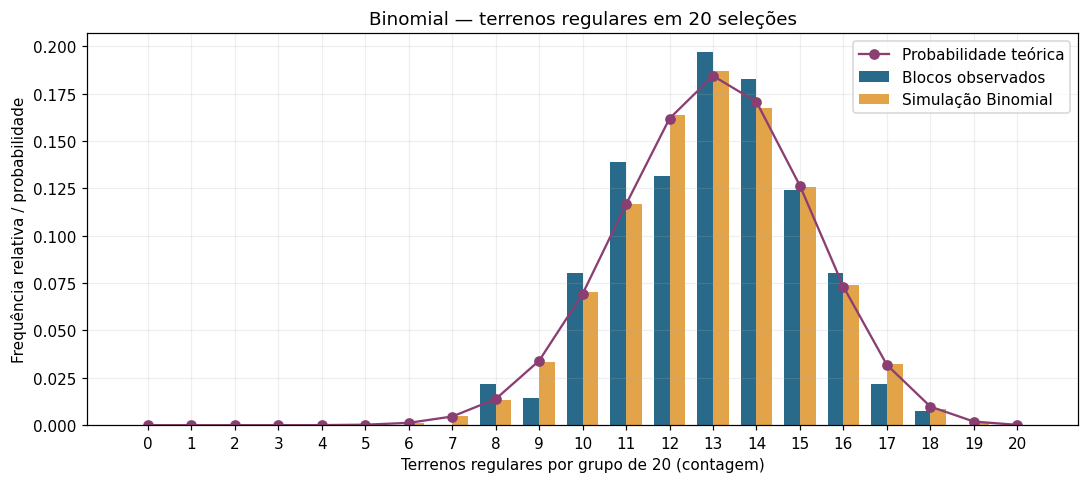

In [6]:
x_bin_sim = rng_binomial.binomial(n=n, p=p, size=N_SIM)
comparacao_bin = pd.DataFrame({
    'Referência': ['Teoria Binomial', 'Blocos de registros observados (sem reposição)',
                   'Simulação Binomial (com reposição)'],
    'Média': [media_bin, x_observado.mean(), x_bin_sim.mean()],
    'Variância': [var_bin, x_observado.var(ddof=1), x_bin_sim.var(ddof=1)],
    'Número de realizações': [np.nan, len(x_observado), N_SIM]
})
display(comparacao_bin)
k_bin = np.arange(n+1)
frequencia_sim_bin = pd.Series(x_bin_sim).value_counts(normalize=True).reindex(k_bin, fill_value=0)
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(k_bin-0.18, freq_blocos, width=0.36, label='Blocos observados', color='#296989')
ax.bar(k_bin+0.18, frequencia_sim_bin, width=0.36, label='Simulação Binomial', color='#e3a348')
ax.plot(k_bin, binom.pmf(k_bin, n, p), 'o-', color='#8b3e72', label='Probabilidade teórica')
ax.set(title='Binomial — terrenos regulares em 20 seleções',
       xlabel='Terrenos regulares por grupo de 20 (contagem)', ylabel='Frequência relativa / probabilidade')
ax.set_xticks(k_bin)
ax.legend()
fig.tight_layout()
plt.show()


In [7]:
display(Markdown(
    f'**Interpretação:** o evento terreno regular representa **{p:.2%}** dos registros válidos. '
    f'A massa teórica concentra-se perto de **{media_bin:.2f}** sucessos por grupo de 20. '
    f'Nos blocos, a média é **{x_observado.mean():.2f}** e a variância **{x_observado.var(ddof=1):.2f}**; '
    f'na simulação, são **{x_bin_sim.mean():.2f}** e **{x_bin_sim.var(ddof=1):.2f}**. '
    'O gráfico permite comparar a concentração dos blocos com a massa teórica; '
    'oscilações nas barras são esperadas com poucos blocos e a restrição sem reposição. '
    'A proximidade entre simulação e teoria confirma o funcionamento computacional do modelo, '
    'mas não demonstra, sozinha, adequação aos registros reais.'
))


**Interpretação:** o evento terreno regular representa **64.93%** dos registros válidos. A massa teórica concentra-se perto de **12.99** sucessos por grupo de 20. Nos blocos, a média é **12.98** e a variância **4.15**; na simulação, são **12.97** e **4.51**. O gráfico permite comparar a concentração dos blocos com a massa teórica; oscilações nas barras são esperadas com poucos blocos e a restrição sem reposição. A proximidade entre simulação e teoria confirma o funcionamento computacional do modelo, mas não demonstra, sozinha, adequação aos registros reais.

## 6. Auditoria dos pressupostos

| Pressuposto | Evidência e limite |
|---|---|
| Número fixo de ensaios | Cada realização tem exatamente 20 seleções. Blocos incompletos não foram usados. |
| Dois resultados | `Reg` versus os demais formatos válidos; ausência não vira fracasso. |
| Probabilidade constante | Com reposição e seleção uniforme, cada ensaio tem o mesmo $p$. Bairros e outros estratos podem apresentar proporções diferentes; o sorteio não é estratificado. |
| Independência | As seleções com reposição são independentes por desenho. Relações espaciais entre imóveis não comprovam independência de um processo de mercado. |
| Seleções em conjunto finito | Sem reposição, a probabilidade muda a cada extração: o modelo exato é Hipergeométrico. A correção de variância foi exibida. Os blocos usados como referência também não são mutuamente independentes. |
| Comparação numérica e gráfica | Usa a mesma escala de 0 a 20 e frequências relativas. A simulação reproduz teoria; os blocos oferecem uma comparação descritiva limitada. |

## 7. Parecer de adequação — Binomial

**Adequado para a finalidade explicitamente delimitada: 20 seleções uniformes, independentes e com reposição na base tratada.** O evento tem dois resultados, o total possui suporte de 0 a 20 e o mecanismo mantém $p$ constante. A expectativa, a variância e a concentração gráfica dão significado prático à contagem; a simulação reproduz essas propriedades.

Para **seleções sem reposição**, a Binomial é apenas uma aproximação: a Hipergeométrica é exata e sua correção de variância quantifica a diferença neste conjunto. A concordância aproximada dos blocos com a Binomial não elimina essa distinção. O parecer não afirma que o mercado gera imóveis independentemente nem que a frequência da base estime uma população externa.


# Trilha 2 — Poisson: número de lareiras

## 1. Delimitação da variável aleatória

- **Unidade de análise:** um registro de imóvel vendido na base tratada.
- **Variável:** $Z$ = número de lareiras do imóvel, registrado em `Fireplaces`.
- **Tipo:** quantitativa discreta, contagem inteira não negativa.
- **Suporte observado:** os valores distintos efetivamente presentes serão exibidos abaixo.
- **Suporte do modelo:** $\{0,1,2,\ldots\}$, sem limite superior.
- **Pergunta específica:** Poisson, calibrada pela média observada, representa a distribuição do número de lareiras por imóvel na base tratada?

## 2. Compatibilidade inicial — antes dos cálculos e gráficos

| Aspecto | Compatibilidade a investigar |
|---|---|
| Tipo | `Fireplaces` é uma contagem inteira não negativa. |
| Suporte | O modelo não tem limite superior; imóveis possuem restrições físicas. O máximo observado não prova um teto universal. |
| Mecanismo | Trata-se do estoque de lareiras existentes, não de eventos registrados ao longo de um intervalo. |
| Exposição | Pode-se definir uma unidade como “um imóvel”, mas isso não equaliza tamanho, número de cômodos ou oportunidade de instalação. |
| Parâmetro | $\lambda$ será calibrado pela média observada. |
| Pressupostos | Taxa comum e independência das ocorrências precisam ser justificadas; média, variância e zeros serão confrontados. |

A variável permite calcular um candidato Poisson, mas sua interpretação física e o mecanismo permanecem em investigação.


## 3. Descrição empírica


In [8]:
frequencia_lareiras = lareiras.value_counts().sort_index().to_frame('Imóveis')
frequencia_lareiras['Frequência relativa'] = frequencia_lareiras['Imóveis'] / len(lareiras)
frequencia_lareiras.index.name = 'Número de lareiras'
display(frequencia_lareiras)
media_obs_pois = lareiras.mean()
var_obs_pois = lareiras.var(ddof=1)
zeros_obs = lareiras.eq(0).mean()
display(pd.DataFrame({'Valor': {
    'Observações válidas': len(lareiras),
    'Ausentes': df['Fireplaces'].isna().sum(),
    'Média (lareiras)': media_obs_pois,
    'Variância amostral (lareiras²)': var_obs_pois,
    'Mínimo': lareiras.min(), 'Mediana': lareiras.median(),
    'Máximo': lareiras.max(), 'Assimetria': lareiras.skew(),
    'Frequência de zeros': zeros_obs
}}))
print('Suporte observado:', sorted(lareiras.unique().tolist()))


Suporte observado: [0, 1, 2, 3, 4]


,Imóveis,Frequência relativa
Número de lareiras,,
0,1417,0.513964
1,1153,0.418208
2,179,0.064926
3,7,0.002539
4,1,0.000363


,Valor
Observações válidas,2757.000000
Ausentes,0.000000
Média (lareiras),0.557127
Variância amostral (lareiras²),0.396318
Mínimo,0.000000
Mediana,0.000000
Máximo,4.000000
Assimetria,0.779590
Frequência de zeros,0.513964


## 4. Modelo candidato e parâmetros

$$Z\sim\operatorname{Poisson}(\lambda),\qquad\lambda=\overline{z}.$$

$$P(Z=k)=\frac{e^{-\lambda}\lambda^k}{k!},\quad E(Z)=\lambda,\quad\operatorname{Var}(Z)=\lambda.$$

O parâmetro expressa o número médio de lareiras por imóvel no candidato calibrado, sem inferência para uma população. A igualdade de média e variância é uma propriedade necessária do modelo, mas sua proximidade isolada não provaria adequação.


In [9]:
lambda_pois = media_obs_pois
razao_disp = var_obs_pois/lambda_pois if lambda_pois > 0 else np.nan
zero_teorico = poisson.pmf(0, lambda_pois)
print(f'λ = {lambda_pois:.6f} lareiras por imóvel')
print(f'E(Z) = Var(Z) = {lambda_pois:.6f} (nas respectivas unidades)')
print(f'Variância observada / média = {razao_disp:.6f}')
print(f'Zeros observados: {zeros_obs:.2%}; zeros Poisson: {zero_teorico:.2%}')
print(f'Diferença de zeros: {(zeros_obs-zero_teorico)*100:.2f} pontos percentuais')
print(f'Probabilidade teórica acima do máximo observado: {poisson.sf(lareiras.max(), lambda_pois):.6%}')


λ = 0.557127 lareiras por imóvel
E(Z) = Var(Z) = 0.557127 (nas respectivas unidades)
Variância observada / média = 0.711360
Zeros observados: 51.40%; zeros Poisson: 57.29%
Diferença de zeros: -5.89 pontos percentuais
Probabilidade teórica acima do máximo observado: 0.028206%


## 5. Simulação reproduzível e comparação — 10.000 realizações


,Referência,Média (lareiras),Variância (lareiras²),Frequência de zeros,Número de realizações
0,Teoria Poisson,0.557127,0.557127,0.572852,NaN
1,Imóveis observados,0.557127,0.396318,0.513964,2757.0
2,Simulação Poisson,0.566100,0.565687,0.568900,10000.0


,Observada,Simulada,Teórica
Lareiras por imóvel,,,
0,0.513964,0.5689,0.572852
1,0.418208,0.3174,0.319152
2,0.064926,0.0957,0.088904
3,0.002539,0.0150,0.016510
4,0.000363,0.0028,0.002300
≥5,0.000000,0.0002,0.000282


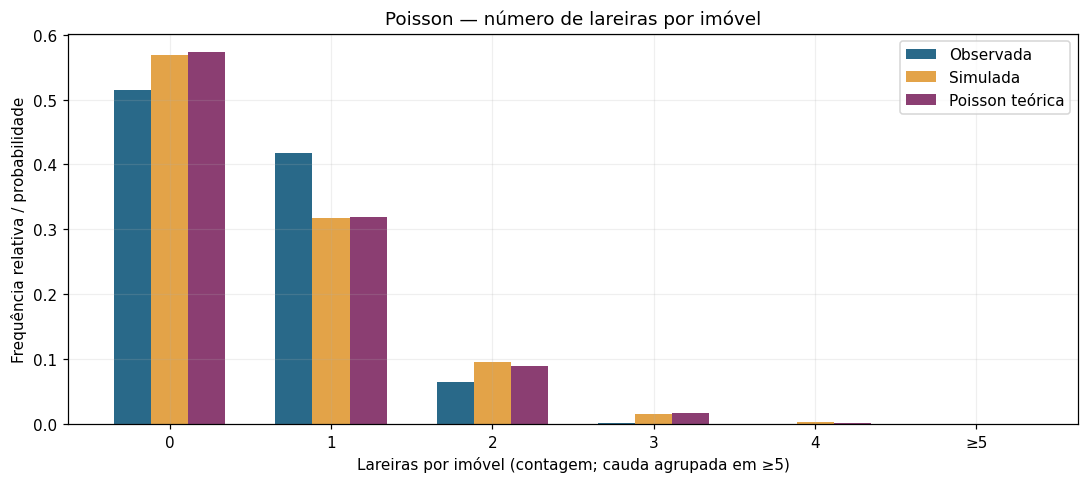

In [10]:
z_pois_sim = rng_poisson.poisson(lam=lambda_pois, size=N_SIM)
comparacao_pois = pd.DataFrame({
    'Referência': ['Teoria Poisson', 'Imóveis observados', 'Simulação Poisson'],
    'Média (lareiras)': [lambda_pois, media_obs_pois, z_pois_sim.mean()],
    'Variância (lareiras²)': [lambda_pois, var_obs_pois, z_pois_sim.var(ddof=1)],
    'Frequência de zeros': [zero_teorico, zeros_obs, (z_pois_sim==0).mean()],
    'Número de realizações': [np.nan, len(lareiras), N_SIM]
})
display(comparacao_pois)

# Agrupamento somente visual da cauda: preserva toda a massa (inclusive acima de 4).
# Não transforma a variável nem usa contagens por faixa como novos dados.
k_pois = np.arange(5)
obs_pois = [lareiras.eq(k).mean() for k in k_pois] + [lareiras.ge(5).mean()]
sim_pois = [(z_pois_sim==k).mean() for k in k_pois] + [(z_pois_sim>=5).mean()]
teoria_pois = list(poisson.pmf(k_pois, lambda_pois)) + [poisson.sf(4, lambda_pois)]
rotulos = ['0', '1', '2', '3', '4', '≥5']
comparacao_freq = pd.DataFrame({'Observada': obs_pois, 'Simulada': sim_pois,
                               'Teórica': teoria_pois}, index=rotulos)
comparacao_freq.index.name = 'Lareiras por imóvel'
display(comparacao_freq)
posicoes = np.arange(len(rotulos))
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(posicoes-0.23, obs_pois, width=0.23, color='#296989', label='Observada')
ax.bar(posicoes, sim_pois, width=0.23, color='#e3a348', label='Simulada')
ax.bar(posicoes+0.23, teoria_pois, width=0.23, color='#8b3e72', label='Poisson teórica')
ax.set_xticks(posicoes, rotulos)
ax.set(title='Poisson — número de lareiras por imóvel',
       xlabel='Lareiras por imóvel (contagem; cauda agrupada em ≥5)',
       ylabel='Frequência relativa / probabilidade')
ax.legend()
fig.tight_layout()
plt.show()


In [11]:
tipo_dispersao = ('subdispersão' if var_obs_pois < lambda_pois
                  else 'sobredispersão' if var_obs_pois > lambda_pois else 'equidispersão')
display(Markdown(
    f'**Interpretação:** os imóveis concentram-se em zero e uma lareira. '
    f'A média observada é **{media_obs_pois:.4f}** e a variância **{var_obs_pois:.4f}**, '
    f'com razão variância/média de **{razao_disp:.4f}** ({tipo_dispersao} descritiva). '
    f'A Poisson exige variância **{lambda_pois:.4f}**. '
    f'O percentual de zeros é **{zeros_obs:.2%}**, contra **{zero_teorico:.2%}** previsto; '
    'o gráfico e a tabela mostram também como a massa é redistribuída entre uma e mais lareiras. '
    f'A variância simulada é **{z_pois_sim.var(ddof=1):.4f}** e permanece próxima da teoria, '
    'não da dispersão observada. A igualdade entre média teórica e observada resulta da '
    'calibração de λ, não constitui evidência independente de ajuste.'
))


**Interpretação:** os imóveis concentram-se em zero e uma lareira. A média observada é **0.5571** e a variância **0.3963**, com razão variância/média de **0.7114** (subdispersão descritiva). A Poisson exige variância **0.5571**. O percentual de zeros é **51.40%**, contra **57.29%** previsto; o gráfico e a tabela mostram também como a massa é redistribuída entre uma e mais lareiras. A variância simulada é **0.5657** e permanece próxima da teoria, não da dispersão observada. A igualdade entre média teórica e observada resulta da calibração de λ, não constitui evidência independente de ajuste.

## 6. Auditoria dos pressupostos

| Pressuposto | Evidência e avaliação |
|---|---|
| Contagem de ocorrências | Há contagem inteira, mas de equipamentos presentes no imóvel, sem processo de ocorrências sucessivas documentado. |
| Intervalo ou exposição definido | “Um imóvel” é a unidade, mas não oferece exposição homogênea: casas diferem em tamanho, padrão e número de cômodos. Não há intervalo temporal de instalação. |
| Taxa aproximadamente constante | Uma única média resume a base, mas não demonstra taxa comum entre imóveis. Não se assume homogeneidade só por calibrar λ. |
| Independência das ocorrências | Lareiras compartilham o projeto e as limitações físicas de uma casa. A base não registra uma sequência de instalações que permita sustentar independência. |
| Ausência de limite estrutural incompatível | O suporte Poisson é ilimitado; casas possuem limites físicos. Não se conclui que 4 seja um teto universal apenas porque é o máximo observado. A pequena massa teórica acima do máximo observado, sozinha, não rejeita o modelo. |
| Média, variância e zeros | A variância é menor que a média e o percentual de zeros é inferior ao previsto. As divergências são descritivas; nenhum teste formal é aplicado. |
| Simulação | Reproduz a equidispersão do modelo e sua distribuição de massa, enquanto os registros apresentam outra dispersão. Não substitui os dados reais. |

## 7. Parecer de adequação — Poisson

**Inadequado como modelo gerador do número de lareiras por imóvel para a finalidade desta auditoria.** A natureza discreta não basta: não há processo documentado de ocorrências independentes com exposição comparável e taxa constante. As restrições do projeto da casa também não correspondem ao mecanismo padrão de Poisson.

As evidências numéricas e gráficas reforçam a limitação: a variância observada é inferior à média, a frequência de zeros diverge da prevista e a massa em uma lareira difere da distribuição candidata. A simulação recupera as propriedades teóricas, mas não resolve essas diferenças. O parecer integra essas evidências com o mecanismo; não se baseia apenas na razão variância/média ou no aspecto das barras. Não é uma rejeição por teste estatístico nem uma afirmação de que toda contagem imobiliária seja incompatível com Poisson.


# Conclusão

**A adequação depende tanto do mecanismo quanto da distribuição dos dados.**

- **Binomial — terreno regular em 20 seleções:** adequada para o sorteio uniforme, independente e com reposição na base tratada. A dicotomização do formato, o suporte de 0 a 20 e os pressupostos correspondem a esse desenho. A comparação com blocos observados precisa ser lida com a correção finita e a dependência da partição sem reposição.
- **Poisson — número de lareiras:** inadequada como modelo gerador na finalidade investigada. Embora a variável seja uma contagem válida, faltam sustentação para exposição comparável e ocorrências independentes; a menor dispersão e a distribuição de zeros e de uma lareira reforçam o parecer.

**Limites:** os dados são os imóveis de Ames presentes no CSV tratado da AP1. A remoção anterior de imóveis de maior preço ou área restringe a descrição e pode modificar as frequências de terreno e lareiras. Essa decisão é preservada. Os parâmetros são calibrações empíricas, os blocos são derivados dos registros e as 10.000 realizações de cada modelo são instrumentos computacionais, não novas bases. Não se generaliza para outros mercados.

Foram realizadas apenas as duas trilhas solicitadas, sem testes de aderência ou normalidade, máxima verossimilhança, seleção automática de distribuições ou transformações para obter ajuste. A trilha Normal não integra este notebook.
